Instalar librerías

In [18]:
!pip install -q openmeteo-requests requests-cache retry-requests pandas numpy matplotlib seaborn folium

Descargar clima real de Guayaquil 2026 (Open-Meteo)
Descarga temperatura, humedad y precipitación hora por hora en horario local de Guayaquil y guarda

In [19]:
import openmeteo_requests
import requests_cache
import pandas as pd
from retry_requests import retry

cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

GUAYAQUIL = {"lat": -2.1700, "lon": -79.9224}

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": GUAYAQUIL["lat"],
    "longitude": GUAYAQUIL["lon"],
    "start_date": "2026-01-01",
    "end_date": "2026-11-20",
    "hourly": ["temperature_2m", "relative_humidity_2m", "precipitation"],
    "timezone": "America/Guayaquil"
}

responses = openmeteo.weather_api(url, params=params)
hourly = responses[0].Hourly()

fechas_utc = pd.date_range(
    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
    freq=pd.Timedelta(seconds=hourly.Interval()),
    inclusive="left"
)
fechas_gye = fechas_utc.tz_convert("America/Guayaquil").tz_localize(None)

df_clima = pd.DataFrame({
    "fecha": fechas_gye,
    "temperatura": hourly.Variables(0).ValuesAsNumpy(),
    "humedad": hourly.Variables(1).ValuesAsNumpy(),
    "precipitacion": hourly.Variables(2).ValuesAsNumpy(),
}).dropna()

df_clima.to_csv("clima_guayaquil_2026.csv", index=False)

print("✅ Descarga completa - Clima Real Guayaquil 2026")
print(f"Total registros horarios: {len(df_clima):,}")
print(f"Rango: {df_clima['fecha'].min()} → {df_clima['fecha'].max()}")
print(f"Temp. promedio: {df_clima['temperatura'].mean():.2f} °C | Máx: {df_clima['temperatura'].max():.2f} °C")
print(f"Precipitación acumulada: {df_clima['precipitacion'].sum():.1f} mm")
df_clima.head()

✅ Descarga completa - Clima Real Guayaquil 2026
Total registros horarios: 7,776
Rango: 2026-01-01 00:00:00 → 2026-11-20 23:00:00
Temp. promedio: 26.96 °C | Máx: 35.25 °C
Precipitación acumulada: 2420.3 mm


,fecha,temperatura,humedad,precipitacion
0,2026-01-01 00:00:00,23.799999,80.537613,0.4
1,2026-01-01 01:00:00,23.850000,79.063698,0.2
2,2026-01-01 02:00:00,23.500000,80.000870,0.0
3,2026-01-01 03:00:00,23.299999,80.721581,0.0
4,2026-01-01 04:00:00,23.100000,81.450157,0.0


Añadir índice ONI y fase de El Niño (2026)
Agrega el índice oficial ONI de la NOAA para cada mes de 2026 y etiqueta cada registro como

In [22]:
oni_data_2026 = {
    "2026-01": -0.40, "2026-02": -0.21, "2026-03":  0.11, "2026-04":  0.46,
    "2026-05":  0.95, "2026-06":  1.39, "2026-07":  1.80, "2026-08":  2.16,
    "2026-09":  2.46, "2026-10":  2.50, "2026-11":  2.50,
}

def clasificar_fase(oni):
    if oni >= 0.5:
        return "El Niño"
    elif oni <= -0.5:
        return "La Niña"
    else:
        return "Neutro"

df_clima["mes_clave"] = df_clima["fecha"].dt.strftime("%Y-%m")
df_clima["oni"] = df_clima["mes_clave"].map(oni_data_2026)
df_clima["fase_climatica"] = df_clima["oni"].apply(clasificar_fase)
df_clima = df_clima.drop(columns=["mes_clave"])

print("Índice ONI 2026 añadido")
print(df_clima["fase_climatica"].value_counts())

Índice ONI 2026 añadido
fase_climatica
El Niño    4896
Neutro     2880
Name: count, dtype: int64


Generar demanda eléctrica y pérdidas por sector
Cruza el clima real con los 6 sectores de Guayaquil, calcula la demanda horaria (MW) y las pérdidas energéticas, y guarda

In [23]:
import numpy as np

np.random.seed(42)

sectores_gye = {
    "Norte (Urdesa-Kennedy)":  {"base_mw": 85, "perdida_base": 12.0},
    "Vía a la Costa":          {"base_mw": 45, "perdida_base": 9.5},
    "Centro":                  {"base_mw": 60, "perdida_base": 11.0},
    "Sur (Guasmo-Trinitaria)": {"base_mw": 70, "perdida_base": 19.0},
    "Durán":                   {"base_mw": 40, "perdida_base": 21.5},
    "Samborondón":             {"base_mw": 35, "perdida_base": 8.5},
}

registros = []
for sector, cfg in sectores_gye.items():
    df_temp = df_clima.copy()
    df_temp["sector"] = sector
    df_temp["demanda_base"] = cfg["base_mw"]
    df_temp["perdida_base"] = cfg["perdida_base"]
    registros.append(df_temp)

df_completo = pd.concat(registros, ignore_index=True)
df_completo["hora"] = df_completo["fecha"].dt.hour
df_completo["dia_semana"] = df_completo["fecha"].dt.dayofweek
df_completo["mes"] = df_completo["fecha"].dt.month

# Factores de comportamiento eléctrico
patron_horario = (
    0.75
    + 0.25 * np.sin((df_completo["hora"] - 6) * np.pi / 12)
    + 0.35 * np.exp(-((df_completo["hora"] - 19) ** 2) / 8)
    + 0.15 * np.exp(-((df_completo["hora"] - 8) ** 2) / 4)
)
factor_finde = np.where(df_completo["dia_semana"] >= 5, 0.88, 1.0)
factor_temp = 1 + 0.022 * (df_completo["temperatura"] - 25).clip(lower=0)
factor_lluvia = 1 - 0.05 * (df_completo["precipitacion"] > 2).astype(int)
factor_oni = 1 + 0.03 * df_completo["oni"].clip(lower=0)

df_completo["demanda_mw"] = (
    df_completo["demanda_base"]
    * patron_horario
    * factor_finde
    * factor_temp
    * factor_lluvia
    * factor_oni
    + np.random.normal(0, 2.5, len(df_completo))
).clip(lower=15).round(2)

# Pérdidas energéticas (%) con picos anómalos (~2% de los registros)
ruido_perdida = np.random.normal(0, 1.5, len(df_completo))
extra_nino = 0.6 * df_completo["oni"].clip(lower=0)
picos_anomalos = np.where(np.random.rand(len(df_completo)) < 0.02, np.random.uniform(8, 15, len(df_completo)), 0)

df_completo["porcentaje_perdida"] = (
    df_completo["perdida_base"] + extra_nino + ruido_perdida + picos_anomalos
).clip(lower=3.0, upper=45.0).round(2)

df_completo["perdida_mw"] = (
    df_completo["demanda_mw"] * (df_completo["porcentaje_perdida"] / 100)
).round(2)

df_completo = df_completo.drop(columns=["demanda_base", "perdida_base"])
df_completo.to_csv("dataset_siep_gye_2026.csv", index=False)

print(f"Dataset generado: {len(df_completo):,} registros")
print(df_completo.groupby("sector")["demanda_mw"].describe()[["mean", "min", "max"]].round(2))

Dataset generado: 46,656 registros
                          mean    min     max
sector                                       
Centro                   53.56  19.07   81.29
Durán                    35.66  15.00   56.78
Norte (Urdesa-Kennedy)   75.86  31.86  115.24
Samborondón              31.33  15.00   50.79
Sur (Guasmo-Trinitaria)  62.47  25.48   95.25
Vía a la Costa           40.19  15.00   62.39


Gráficos exploratorios (para tu informe)
Genera los 4 gráficos principales del análisis exploratorio de 2026.

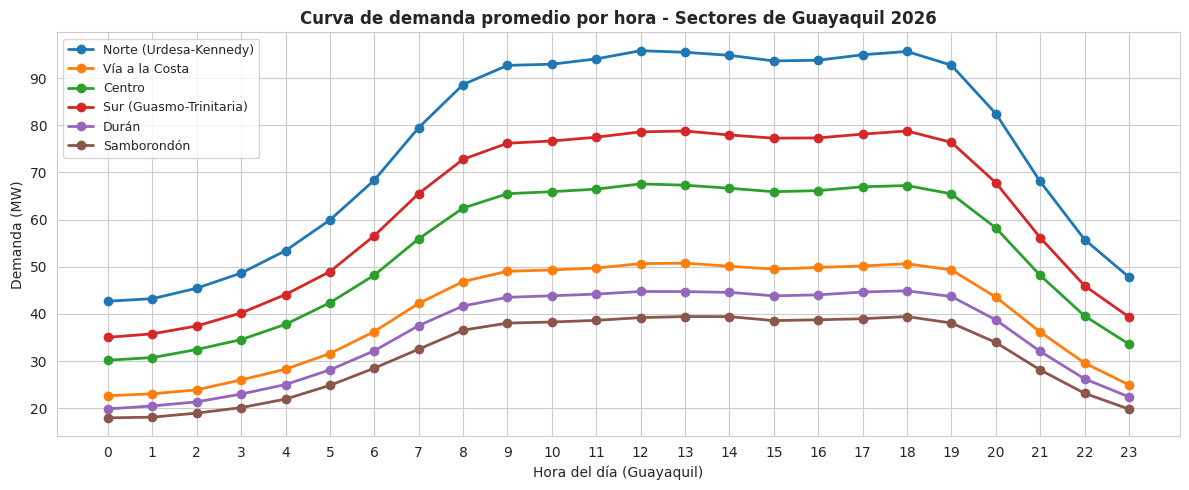

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Curva horaria
fig, ax = plt.subplots(figsize=(12, 5))
for sector in df_completo["sector"].unique():
    data = df_completo[df_completo["sector"] == sector].groupby("hora")["demanda_mw"].mean()
    ax.plot(data.index, data.values, marker="o", linewidth=2, label=sector)
ax.set_title("Curva de demanda promedio por hora - Sectores de Guayaquil 2026", fontweight="bold")
ax.set_xlabel("Hora del día (Guayaquil)")
ax.set_ylabel("Demanda (MW)")
ax.set_xticks(range(0, 24))
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()



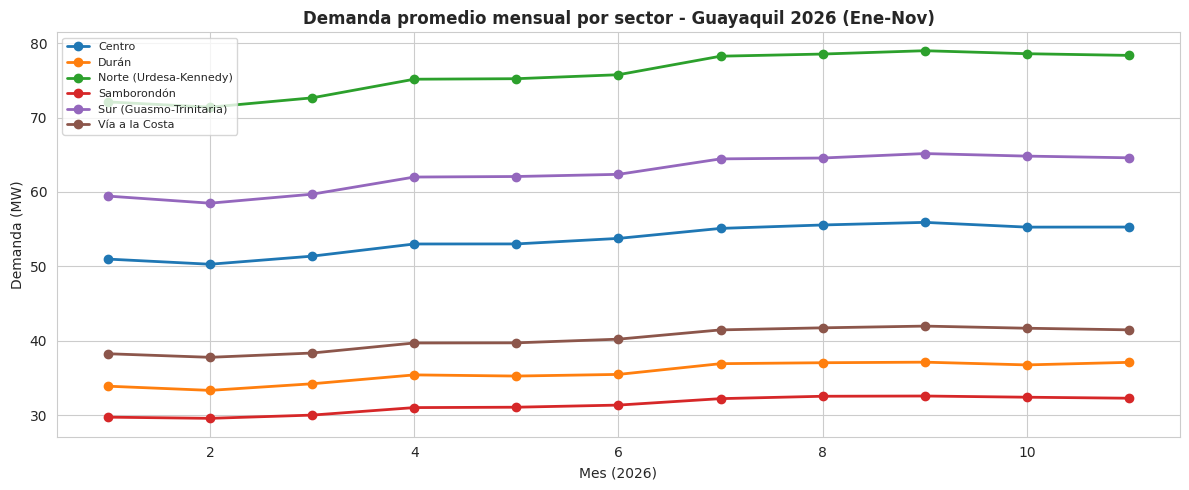

In [26]:
# 2. Evolución mensual
fig, ax = plt.subplots(figsize=(12, 5))
df_completo.groupby(["mes", "sector"])["demanda_mw"].mean().unstack().plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Demanda promedio mensual por sector - Guayaquil 2026 (Ene-Nov)", fontweight="bold")
ax.set_xlabel("Mes (2026)")
ax.set_ylabel("Demanda (MW)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

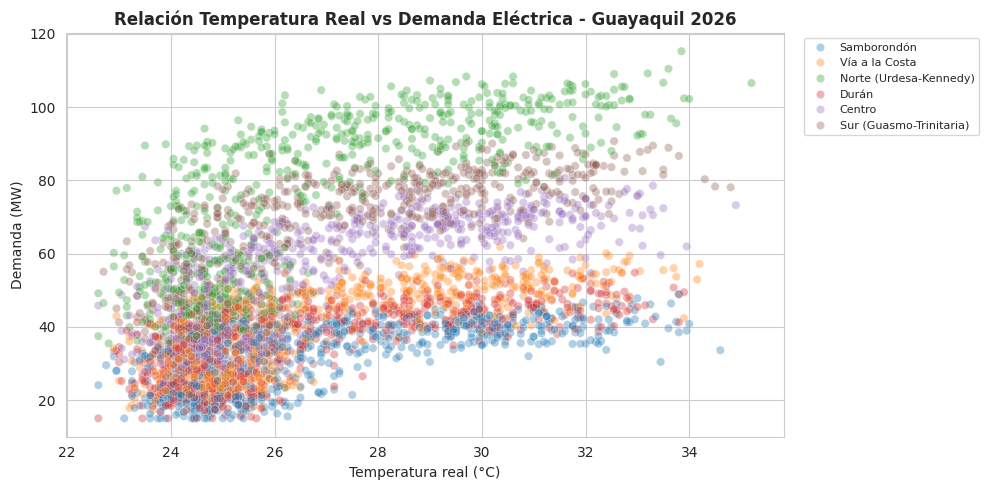

In [27]:
# 3. Temperatura vs Demanda
fig, ax = plt.subplots(figsize=(10, 5))
muestra = df_completo.sample(min(4000, len(df_completo)), random_state=42)
sns.scatterplot(data=muestra, x="temperatura", y="demanda_mw", hue="sector", alpha=0.35, ax=ax)
ax.set_title("Relación Temperatura Real vs Demanda Eléctrica - Guayaquil 2026", fontweight="bold")
ax.set_xlabel("Temperatura real (°C)")
ax.set_ylabel("Demanda (MW)")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

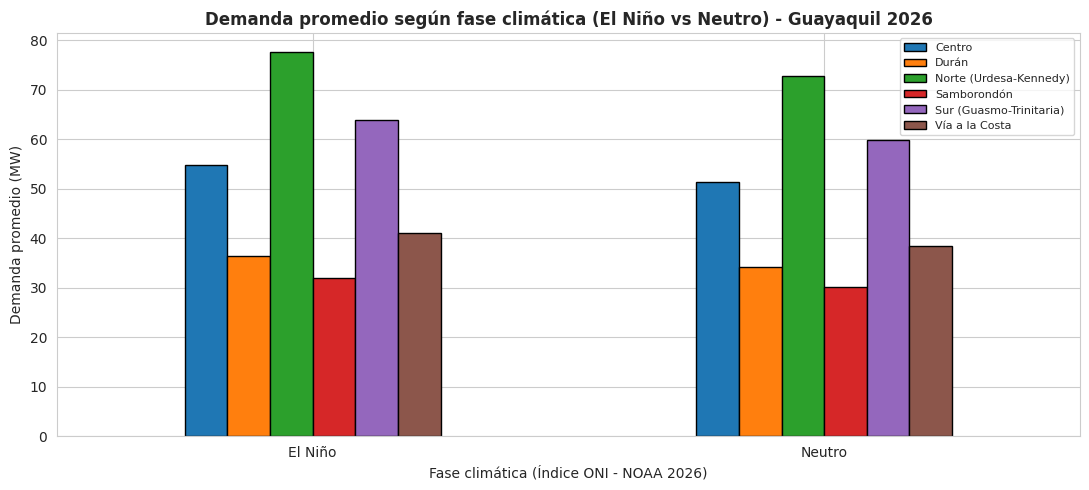

In [28]:
# 4. El Niño vs Fase Neutra
fig, ax = plt.subplots(figsize=(11, 5))
df_completo.groupby(["fase_climatica", "sector"])["demanda_mw"].mean().unstack().plot(
    kind="bar", ax=ax, edgecolor="black"
)
ax.set_title("Demanda promedio según fase climática (El Niño vs Neutro) - Guayaquil 2026", fontweight="bold")
ax.set_xlabel("Fase climática (Índice ONI - NOAA 2026)")
ax.set_ylabel("Demanda promedio (MW)")
ax.legend(fontsize=8, loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
from google.colab import drive
import shutil

drive.mount('/content/drive')
shutil.copy("dataset_siep_gye_2026.csv", "/content/drive/MyDrive/dataset_siep_gye_2026.csv")
shutil.copy("clima_guayaquil_2026.csv", "/content/drive/MyDrive/clima_guayaquil_2026.csv")

print("Archivos respaldados en tu Google Drive.")

Mounted at /content/drive
Archivos respaldados en tu Google Drive.


In [30]:

import os
from pathlib import Path

carpeta = Path("/content")

print("ARCHIVOS DEL PROYECTO SIEP-GYE\n")

for archivo in carpeta.rglob("*"):
    if archivo.is_file():
        if archivo.suffix.lower() in [
            ".csv", ".xlsx", ".xls", ".ipynb",
            ".joblib", ".pkl", ".h5", ".keras",
            ".py", ".json", ".txt"
        ]:
            tamaño = archivo.stat().st_size / 1024

            print(
                f"{archivo.relative_to(carpeta)} "
                f"- {tamaño:.2f} KB"
            )


ARCHIVOS DEL PROYECTO SIEP-GYE

clima_real_siep_gye_2024.csv - 276.98 KB
clima_guayaquil_2026.csv - 294.40 KB
oni_real_siep_gye_2024.csv - 0.53 KB
dataset_siep_gye_2026.csv - 4116.68 KB
.config/.last_update_check.json - 0.13 KB
sample_data/anscombe.json - 1.66 KB
sample_data/california_housing_train.csv - 1666.44 KB
sample_data/mnist_test.csv - 17860.78 KB
sample_data/mnist_train_small.csv - 35667.85 KB
sample_data/california_housing_test.csv - 294.08 KB
drive/MyDrive/nvda_precios_con_errores.csv - 8.94 KB
drive/MyDrive/u2_s4_taller_en_clase_predicción_vinos (2).py - 3.57 KB
drive/MyDrive/dataset_siep_gye_2026.csv - 4116.68 KB
drive/MyDrive/clima_guayaquil_2026.csv - 294.40 KB
drive/MyDrive/Colab Notebooks/Práctica Unidad 1.ipynb - 156.49 KB
drive/MyDrive/Colab Notebooks/Untitled0.ipynb - 0.32 KB
drive/MyDrive/Colab Notebooks/Untitled1.ipynb - 0.32 KB
drive/MyDrive/Colab Notebooks/Untitled2.ipynb - 74.59 KB
drive/MyDrive/Colab Notebooks/Copia de Untitled2.ipynb - 74.66 KB
drive/MyDri

In [31]:

import pandas as pd
import os

archivos = [
    "/content/dataset_siep_gye_2026.csv",
    "/content/clima_guayaquil_2026.csv",
    "/content/clima_real_siep_gye_2024.csv",
    "/content/oni_real_siep_gye_2024.csv"
]

for ruta in archivos:

    if os.path.exists(ruta):

        print("\n" + "=" * 65)
        print("ARCHIVO:", os.path.basename(ruta))
        print("=" * 65)

        df = pd.read_csv(ruta)

        print("Dimensiones:", df.shape)
        print("\nColumnas:")
        print(df.columns.tolist())

        print("\nPrimeros 5 registros:")
        display(df.head())

        print("\nValores faltantes:")
        print(df.isnull().sum())

    else:
        print("\nNo encontrado:", ruta)



ARCHIVO: dataset_siep_gye_2026.csv
Dimensiones: (46656, 13)

Columnas:
['fecha', 'temperatura', 'humedad', 'precipitacion', 'oni', 'fase_climatica', 'sector', 'hora', 'dia_semana', 'mes', 'demanda_mw', 'porcentaje_perdida', 'perdida_mw']

Primeros 5 registros:


,fecha,temperatura,humedad,precipitacion,oni,fase_climatica,sector,hora,dia_semana,mes,demanda_mw,porcentaje_perdida,perdida_mw
0,2026-01-01 00:00:00,23.80,80.53761,0.4,-0.4,Neutro,Norte (Urdesa-Kennedy),0,3,1,43.74,12.86,5.62
1,2026-01-01 01:00:00,23.85,79.06370,0.2,-0.4,Neutro,Norte (Urdesa-Kennedy),1,3,1,42.88,9.41,4.04
2,2026-01-01 02:00:00,23.50,80.00087,0.0,-0.4,Neutro,Norte (Urdesa-Kennedy),2,3,1,46.97,8.92,4.19
3,2026-01-01 03:00:00,23.30,80.72158,0.0,-0.4,Neutro,Norte (Urdesa-Kennedy),3,3,1,52.56,12.39,6.51
4,2026-01-01 04:00:00,23.10,81.45016,0.0,-0.4,Neutro,Norte (Urdesa-Kennedy),4,3,1,52.77,12.02,6.34



Valores faltantes:
fecha                 0
temperatura           0
humedad               0
precipitacion         0
oni                   0
fase_climatica        0
sector                0
hora                  0
dia_semana            0
mes                   0
demanda_mw            0
porcentaje_perdida    0
perdida_mw            0
dtype: int64

ARCHIVO: clima_guayaquil_2026.csv
Dimensiones: (7776, 4)

Columnas:
['fecha', 'temperatura', 'humedad', 'precipitacion']

Primeros 5 registros:


,fecha,temperatura,humedad,precipitacion
0,2026-01-01 00:00:00,23.80,80.53761,0.4
1,2026-01-01 01:00:00,23.85,79.06370,0.2
2,2026-01-01 02:00:00,23.50,80.00087,0.0
3,2026-01-01 03:00:00,23.30,80.72158,0.0
4,2026-01-01 04:00:00,23.10,81.45016,0.0



Valores faltantes:
fecha            0
temperatura      0
humedad          0
precipitacion    0
dtype: int64

ARCHIVO: clima_real_siep_gye_2024.csv
Dimensiones: (2196, 11)

Columnas:
['fecha', 'temperatura_promedio', 'temperatura_maxima', 'temperatura_minima', 'humedad_promedio', 'precipitacion_total', 'sensacion_termica', 'sector', 'latitud', 'longitud', 'fuente']

Primeros 5 registros:


,fecha,temperatura_promedio,temperatura_maxima,temperatura_minima,humedad_promedio,precipitacion_total,sensacion_termica,sector,latitud,longitud,fuente
0,2024-01-01,26.387500,31.0,24.1,79.250000,1.2,30.441667,Centro,-2.196,-79.886,Open-Meteo Historical Weather API
1,2024-01-01,26.375000,31.1,23.6,79.583333,2.4,30.491667,Duran,-2.170,-79.830,Open-Meteo Historical Weather API
2,2024-01-01,26.470833,31.4,24.0,78.666667,1.9,30.641667,Norte,-2.167,-79.910,Open-Meteo Historical Weather API
3,2024-01-01,26.470833,31.4,24.0,78.666667,1.9,30.641667,Samborondon,-2.140,-79.870,Open-Meteo Historical Weather API
4,2024-01-01,26.570833,31.0,24.4,78.708333,1.8,30.545833,Sur,-2.270,-79.890,Open-Meteo Historical Weather API



Valores faltantes:
fecha                   0
temperatura_promedio    0
temperatura_maxima      0
temperatura_minima      0
humedad_promedio        0
precipitacion_total     0
sensacion_termica       0
sector                  0
latitud                 0
longitud                0
fuente                  0
dtype: int64

ARCHIVO: oni_real_siep_gye_2024.csv
Dimensiones: (12, 4)

Columnas:
['fecha', 'temporada', 'oni', 'fuente']

Primeros 5 registros:


,fecha,temporada,oni,fuente
0,2024-01-01,DJF,1.8,NOAA CPC - ONI ERSSTv6
1,2024-02-01,JFM,1.5,NOAA CPC - ONI ERSSTv6
2,2024-03-01,FMA,1.2,NOAA CPC - ONI ERSSTv6
3,2024-04-01,MAM,0.8,NOAA CPC - ONI ERSSTv6
4,2024-05-01,AMJ,0.4,NOAA CPC - ONI ERSSTv6



Valores faltantes:
fecha        0
temporada    0
oni          0
fuente       0
dtype: int64
